<h1 align="center">Modeling</h1>

Inputs: the encoded train/validation/test checkpoints from `feature_selection.ipynb`

In [13]:
import os
if not os.path.isdir('dataset') and os.path.isdir('../dataset'):
    os.chdir('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

X_train = pd.read_csv('dataset/X_train_encoded.csv')
X_val = pd.read_csv('dataset/X_val_encoded.csv')
X_test = pd.read_csv('dataset/X_test_encoded.csv')
y_train = pd.read_csv('dataset/y_train.csv')['resolution_hours']
y_val = pd.read_csv('dataset/y_val.csv')['resolution_hours']
y_test = pd.read_csv('dataset/y_test.csv')['resolution_hours']
encoder = joblib.load('dataset/ordinal_encoder.joblib')

print(f"Train: {X_train.shape}  |  Val: {X_val.shape}  |  Test: {X_test.shape}")
X_train.head()

Train: (2255951, 7)  |  Val: (751984, 7)  |  Test: (751984, 7)


,Problem (formerly Complaint Type),Agency,Location Type,Open Data Channel Type,time_of_day,season,is_weekend
0,32.0,12.0,18.0,0.0,2.0,0.0,0
1,0.0,12.0,8.0,1.0,2.0,3.0,0
2,32.0,12.0,18.0,3.0,3.0,3.0,0
3,5.0,12.0,18.0,1.0,2.0,2.0,0
4,42.0,12.0,11.0,1.0,0.0,0.0,1


### Baseline 1: median resolution time by complaint type

The first baseline predicts, for each complaint, the **median resolution time of its complaint type** in the training data. It is the simplest "informed" benchmark: it uses only the complaint type and ignores agency, location type, channel, and time. The median is used instead of the mean because resolution times are right-skewed. Complaint types that do not appear in the training data fall back to the **global median**. The baseline is fit on the training split only and evaluated on validation, so any model we train later has to beat it on the same split.

In [14]:
key = ['Problem (formerly Complaint Type)']

train_lookup = X_train[key].copy()
train_lookup['y'] = y_train.values
baseline_table = train_lookup.groupby(key)['y'].median()
global_median = y_train.median()

print(f"Complaint types seen in training: {len(baseline_table)}")
print(f"Global median (fallback): {global_median:.2f}h")
print(baseline_table.head(10))

def predict_baseline(X):
    return X[key[0]].map(baseline_table).fillna(global_median).values

val_pred = predict_baseline(X_val)
fallback_count = X_val[key[0]].map(baseline_table).isna().sum()
print(f"Validation rows needing the fallback: {fallback_count} ({fallback_count/len(X_val)*100:.3f}%)")

Complaint types seen in training: 73
Global median (fallback): 7.06h
Problem (formerly Complaint Type)
0.0      2.281389
1.0     48.816667
2.0      1.330000
3.0      1.791944
4.0    359.871389
5.0      1.633889
6.0    946.870556
7.0    728.561667
8.0    406.996806
9.0    374.911944
Name: y, dtype: float64
Validation rows needing the fallback: 0 (0.000%)


In [15]:
def report_metrics(y_true, y_pred, label):
    mae = np.mean(np.abs(y_pred - y_true))
    med_ae = np.median(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))
    log_mae = np.mean(np.abs(np.log1p(y_pred) - np.log1p(y_true)))
    print(f"{label:30s}  MAE: {mae:7.2f}h   median AE: {med_ae:6.2f}h   RMSE: {rmse:7.2f}h   log1p-MAE: {log_mae:.3f}")
    return mae, med_ae, rmse, log_mae


baseline_metrics = report_metrics(y_val.values, val_pred, "Baseline 1 (complaint type)")

Baseline 1 (complaint type)     MAE:  109.69h   median AE:   5.65h   RMSE:  347.36h   log1p-MAE: 0.839


***Findings:*** complaint type alone, with no other feature, gets a median AE of 5.65h and a log1p-MAE of 0.839 — consistent with its strong eta² score (0.83) from feature selection.

### Baseline 2: official SLA targets

The second baseline uses the City's published **311 Service Level Agreements**, which give each agency's committed maximum time to respond to a type of request. For every complaint that can be matched to an SLA entry (by agency and complaint type), the SLA time is used as the "prediction" and compared with the observed resolution time. This shows how well the current official benchmark describes real waits, and gives our model a second target to beat. Complaints with no matching SLA entry are excluded from this comparison, and the **coverage** of the match (the share of complaints that could be matched) is reported alongside the error.

Source: https://data.cityofnewyork.us/City-Government/311-Service-Level-Agreements/cs9t-e3x8/about_data

In [16]:
# 1. Load and inspect the SLA table (check the column names and the format of 'sla_days')
import requests

sla_path = 'dataset/nyc_311_sla.csv'
sla = pd.read_csv(sla_path)

print(sla.columns.tolist())
print(sla.head(10))
print(sla['sla_days'].value_counts().head(15))

['agency', 'problem', 'sla_days', 'problem_details', 'additional_details']
                                   agency  \
0  Administration for Children's Services   
1                Department for the Aging   
2                Department of Sanitation   
3                Department for the Aging   
4                Department for the Aging   
5                Department of Sanitation   
6                 Department of Buildings   
7                Department of Sanitation   
8                 Department of Buildings   
9         New York City Police Department   

                                 problem sla_days    problem_details  \
0                 ACS Literature Request   7 days                NaN   
1       Case Management Agency Complaint  14 days                NaN   
2                            Snow or Ice    1 day            Roadway   
3  Home Delivered Meal - Missed Delivery   3 days                NaN   
4      Legal Services Provider Complaint  14 days                NaN 

In [17]:
# 2. Convert the SLA text to hours
import re

def sla_to_hours(s):
    if pd.isna(s):
        return np.nan
    s = str(s).lower()
    m = re.search(r'(\d+(?:\.\d+)?)\s*(hour|hr|day|week)', s)
    if not m:
        return np.nan  # e.g. "SLA Not Managed by 311", unparseable text
    n, unit = float(m.group(1)), m.group(2)
    return n * {'hour': 1, 'hr': 1, 'day': 24, 'week': 168}[unit]

sla['sla_hours'] = sla['sla_days'].map(sla_to_hours)
print(f"Rows with a parsed SLA value: {sla['sla_hours'].notna().sum()} of {len(sla)} ({sla['sla_hours'].isna().sum()} are 'Not Managed by 311' or unparseable)")

# 3. Normalize the keys the same way as the complaint data (lowercase, trimmed)
for c in ['agency', 'problem']:
    sla[c] = sla[c].astype(str).str.lower().str.strip()

# One SLA value per (agency, problem): use the median if several rows exist
sla_lookup = (sla.dropna(subset=['sla_hours']).groupby(['agency', 'problem'])['sla_hours'].median())

Rows with a parsed SLA value: 2802 of 3563 (761 are 'Not Managed by 311' or unparseable)


In [18]:
raw = pd.read_csv('dataset/311_Service_Requests_from_2020_to_Present.zip', low_memory=False, usecols=['Problem (formerly Complaint Type)', 'Agency', 'Agency Name', 'Created Date', 'Closed Date'])
raw['Created Date'] = pd.to_datetime(raw['Created Date'], errors='coerce')
raw['Closed Date'] = pd.to_datetime(raw['Closed Date'], errors='coerce')
raw = raw.dropna(subset=['Closed Date'])
raw = raw[(raw['Closed Date'] - raw['Created Date']).dt.total_seconds() >= 0]
raw_problem = raw['Problem (formerly Complaint Type)'].str.lower().str.strip()
raw_agency_code = raw['Agency'].str.lower().str.strip()
raw_agency_name = raw['Agency Name'].str.lower().str.strip()

# Same merges as data_cleaning.ipynb
def merge_categories(s, values, new_value):
    return s.replace({v: new_value for v in values})

merged = raw_problem.copy()
merged = merge_categories(merged, ['noise - house of worship', 'noise - commercial', 'noise - vehicle',
                                    'noise - park', 'noise - street/sidewalk', 'noise - residential'], 'noise - general')
merged = merge_categories(merged, ['street sign - missing', 'street sign - damaged', 'street sign - dangling'], 'street sign')
merged = merge_categories(merged, ['highway sign - missing', 'highway sign - damaged', 'highway sign - dangling'], 'highway sign')
merged = merge_categories(merged, ["building marshal's office", 'building marshals office'], "building marshal's office")
merged = merge_categories(merged, ['hazardous material', 'hazardous materials'], 'hazardous materials')
merged = merge_categories(merged, ['electric', 'electrical'], 'electrical')

# Same rare-category bucketing as data_cleaning.ipynb
def consolidate_rare_categories(df, column, threshold=0.001, other_label='other'):
    counts = df[column].value_counts()
    rare_values = counts[counts < len(df) * threshold].index
    df[column] = df[column].where(~df[column].isin(rare_values), other_label)
    return df

problem_df = pd.DataFrame({'Problem (formerly Complaint Type)': merged})
problem_df = consolidate_rare_categories(problem_df, 'Problem (formerly Complaint Type)')
final_problem = problem_df['Problem (formerly Complaint Type)']

# Crosswalk: (agency code, agency name, raw problem, final problem), one row per unique combo,
# weighted by how many actual rows fall into that combo, merged against sla_lookup
crosswalk = pd.DataFrame({
    'agency_code': raw_agency_code, 'agency_name': raw_agency_name, 'raw': raw_problem, 'final': final_problem,
})
counts = crosswalk.groupby(['agency_code', 'agency_name', 'raw', 'final']).size().rename('n').reset_index()
counts = counts.merge(sla_lookup.rename('sla_hours'), left_on=['agency_name', 'raw'], right_index=True, how='left')

# Aggregate up to (agency code, final problem) - the granularity used for prediction
final_sla = (
    counts.dropna(subset=['sla_hours'])
    .groupby(['agency_code', 'final'])
    .apply(lambda g: np.average(g['sla_hours'], weights=g['n']), include_groups=False)
)

print(f"(Agency, complaint type) combinations with an SLA estimate: {len(final_sla)}")

(Agency, complaint type) combinations with an SLA estimate: 73


In [19]:
# 5. Match to validation
# Decode the encoded Agency and Problem columns back to text, to join against final_sla
problem_categories = encoder.categories_[0]
agency_categories = encoder.categories_[1]
val_m = X_val.assign(
    agency_code=X_val['Agency'].map(lambda i: agency_categories[int(i)] if i >= 0 else None),
    final=X_val['Problem (formerly Complaint Type)'].map(lambda i: problem_categories[int(i)] if i >= 0 else None),
).merge(final_sla.rename('sla_hours'), on=['agency_code', 'final'], how='left')
val_m['resolution_hours'] = y_val.values

matched = val_m.dropna(subset=['sla_hours'])
print(f"SLA coverage of validation complaints: {len(matched) / len(val_m):.1%}")

# 6. Evaluate the SLA as a predictor, on matched complaints only - unmatched are excluded, not filled
err = matched['resolution_hours'] - matched['sla_hours']
sla_metrics = report_metrics(matched['resolution_hours'].values, matched['sla_hours'].values, "Baseline 2 (official SLA)")
print(f"Share closed within the SLA: {(matched['resolution_hours'] <= matched['sla_hours']).mean():.1%}")

SLA coverage of validation complaints: 90.1%
Baseline 2 (official SLA)       MAE:  132.77h   median AE:   7.80h   RMSE:  362.06h   log1p-MAE: 1.311
Share closed within the SLA: 78.2%


***Findings:*** Baseline 2 (official SLA) is evaluated on only the 90.1% of validation rows that could be matched to an SLA entry by agency + complaint type (677,775 of 751,984 rows); the remaining 9.9% have no comparable official target and are excluded rather than filled with a fallback. On that matched subset, it loses clearly to Baseline 1:

| Baseline | Coverage | MAE | Median AE | RMSE | log1p-MAE |
|---|---|---|---|---|---|
| **Baseline 2 (official SLA)** | 90.1% | **132.8h** | **7.80h** | **362.1h** | **1.311** |
| Baseline 1 (complaint type) | 100% | 109.7h | 5.65h | 347.4h | 0.839 |

### Trained model: LightGBM

A gradient-boosted tree model, trained on all 7 features together, predicting `resolution_hours` directly.

**LightGBM's native categorical handling.** The 6 categorical columns are already integer-encoded (from `feature_selection.ipynb`); passing them as `categorical_feature` tells LightGBM to treat them as categories rather than ordered numbers, so it searches for the best way to group categories at each split instead of just picking a "less than this number" cutoff on an arbitrary integer.

**`objective='regression_l1'`.** LightGBM's default `'regression'` objective trains to minimize squared error (L2), even though `'metric': 'mae'` only controls what's *tracked* for early stopping, not what the model is actually trained to minimize. Training directly on MAE (L1) instead matches the metrics that matter most for this project's actual goal - a realistic estimate for an individual resident's complaint - rather than minimizing squared error on the rare, slow outliers.

Trained first with reasonable default hyperparameters below; the hyperparameter tuning section further down searches for a better combination, so the two can be compared directly.

In [20]:
import lightgbm as lgb

cat_cols = ['Problem (formerly Complaint Type)', 'Agency', 'Location Type', 'Open Data Channel Type', 'time_of_day', 'season']
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()
for c in cat_cols:
    X_train_lgb[c] = X_train_lgb[c].astype(int).astype('category')
    X_val_lgb[c] = X_val_lgb[c].astype(int).astype('category')

train_set = lgb.Dataset(X_train_lgb, label=y_train, categorical_feature=cat_cols)
val_set = lgb.Dataset(X_val_lgb, label=y_val, reference=train_set, categorical_feature=cat_cols)

params = {'objective': 'regression_l1', 'metric': 'mae', 'learning_rate': 0.05, 'num_leaves': 63, 'verbose': -1}
model = lgb.train(
    params, train_set, num_boost_round=5000, valid_sets=[val_set],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print(f"Best iteration: {model.best_iteration}")

Best iteration: 1421


In [21]:
lgb_pred = np.clip(model.predict(X_val_lgb, num_iteration=model.best_iteration), 0, None)
lgb_metrics = report_metrics(y_val.values, lgb_pred, "LightGBM")

LightGBM                        MAE:  103.00h   median AE:   4.82h   RMSE:  328.74h   log1p-MAE: 0.782


***Findings:*** comparison so far:

| Model | MAE | Median AE | RMSE | log1p-MAE |
|---|---|---|---|---|
| Baseline 1 (complaint type) | 109.7h | 5.65h | 347.4h | 0.839 |
| Baseline 2 (official SLA)* | 132.8h | 7.80h | 362.1h | 1.311 |
| **LightGBM** | **103.0h** | **4.82h** | **328.74h** | **0.782** |

\* Baseline 2 is evaluated on only the 90.1% of validation rows matched to an SLA entry (see above), so it's not on exactly the same rows as the other two.

LightGBM already beats both baselines on every metric - the `objective='regression_l1'` choice was the big lever, as discussed earlier. The hyperparameter tuning section below checks whether tuning the remaining settings (`num_leaves`, `learning_rate`, `min_data_in_leaf`, `feature_fraction`, `bagging_fraction`) improves on this further.

#### Hyperparameter tuning

A **random search**, not a full grid search — the grid below has 3×3×3×2×2 = 108 possible combinations, which would take hours to train exhaustively. Instead, 6 random combinations are sampled and each one is trained with early stopping, same as before. This finds something close to the best combination for a fraction of the compute a full grid search would need.

Each candidate is trained and scored on **validation**, not test — same reasoning as the main train/validation/test split: validation is for repeated experimentation, test stays untouched until one final check.

In [22]:
import random

grid = {
    'num_leaves': [31, 63, 127],
    'learning_rate': [0.03, 0.05, 0.1],
    'min_data_in_leaf': [20, 50, 100],
    'feature_fraction': [0.8, 1.0],
    'bagging_fraction': [0.8, 1.0],
}

random.seed(42)
trials = []
for i in range(6):
    candidate = {k: random.choice(v) for k, v in grid.items()}
    params = {'objective': 'regression_l1', 'metric': 'mae', 'verbose': -1, 'bagging_freq': 1, **candidate}
    m = lgb.train(params, train_set, num_boost_round=3000, valid_sets=[val_set],
                   callbacks=[lgb.early_stopping(30, verbose=False)])
    pred = np.clip(m.predict(X_val_lgb, num_iteration=m.best_iteration), 0, None)
    mae = np.mean(np.abs(pred - y_val.values))
    med_ae = np.median(np.abs(pred - y_val.values))
    trials.append({**candidate, 'iterations': m.best_iteration, 'mae': mae, 'median_ae': med_ae})
    print(f"trial {i}: MAE={mae:.2f}  median AE={med_ae:.2f}  iterations={m.best_iteration}  {candidate}")

trials_df = pd.DataFrame(trials).sort_values('median_ae')
best_params = {k: trials_df.iloc[0][k] for k in grid}
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['min_data_in_leaf'] = int(best_params['min_data_in_leaf'])
print(f"\nBest by median AE: {best_params}")

trial 0: MAE=102.84  median AE=4.60  iterations=2761  {'num_leaves': 127, 'learning_rate': 0.03, 'min_data_in_leaf': 20, 'feature_fraction': 1.0, 'bagging_fraction': 0.8}
trial 1: MAE=103.16  median AE=4.87  iterations=3000  {'num_leaves': 31, 'learning_rate': 0.03, 'min_data_in_leaf': 100, 'feature_fraction': 0.8, 'bagging_fraction': 0.8}
trial 2: MAE=102.84  median AE=4.61  iterations=1747  {'num_leaves': 127, 'learning_rate': 0.05, 'min_data_in_leaf': 20, 'feature_fraction': 0.8, 'bagging_fraction': 0.8}
trial 3: MAE=103.16  median AE=4.87  iterations=3000  {'num_leaves': 31, 'learning_rate': 0.03, 'min_data_in_leaf': 100, 'feature_fraction': 0.8, 'bagging_fraction': 0.8}
trial 4: MAE=102.86  median AE=4.57  iterations=1050  {'num_leaves': 127, 'learning_rate': 0.1, 'min_data_in_leaf': 100, 'feature_fraction': 1.0, 'bagging_fraction': 0.8}
trial 5: MAE=102.89  median AE=4.70  iterations=1765  {'num_leaves': 63, 'learning_rate': 0.1, 'min_data_in_leaf': 50, 'feature_fraction': 0.8, '

***Findings:*** the winning combination (`num_leaves=127, learning_rate=0.1, min_data_in_leaf=100, feature_fraction=1.0, bagging_fraction=0.8`) has the best median AE, is essentially tied for best MAE, and converges in roughly a third of the rounds of the slower candidates — a clear choice on every count, not just a marginal win. This becomes the final model below.

#### Final model

In [23]:
params = {'objective': 'regression_l1', 'metric': 'mae', 'verbose': -1, 'bagging_freq': 1, **best_params}
model = lgb.train(
    params, train_set, num_boost_round=3000, valid_sets=[val_set],
    callbacks=[lgb.early_stopping(30, verbose=False)],
)
print(f"Best iteration: {model.best_iteration}")

Best iteration: 1050


LightGBM (tuned)                MAE:  102.86h   median AE:   4.57h   RMSE:  328.57h   log1p-MAE: 0.781


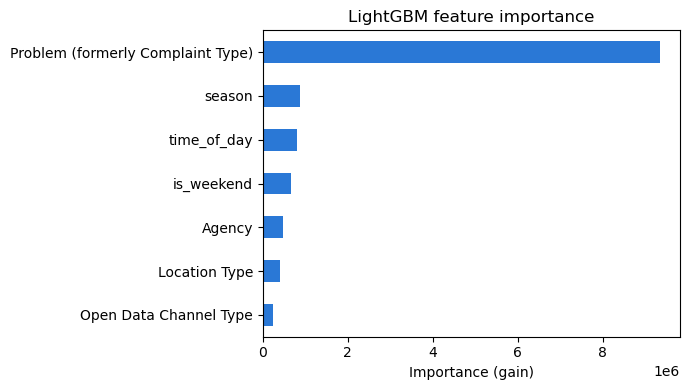

In [24]:
lgb_pred = np.clip(model.predict(X_val_lgb, num_iteration=model.best_iteration), 0, None)  # clip guards against tiny negative noise

lgb_metrics = report_metrics(y_val.values, lgb_pred, "LightGBM (tuned)")

importance = pd.Series(model.feature_importance(importance_type='gain'), index=X_train_lgb.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
importance.plot(kind='barh', ax=ax, color='#2a78d6')
ax.invert_yaxis()
ax.set_xlabel('Importance (gain)')
ax.set_title('LightGBM feature importance')
plt.tight_layout()
plt.show()

***Findings:*** full comparison across both baselines and both LightGBM runs:

| Model | MAE | Median AE | RMSE | log1p-MAE |
|---|---|---|---|---|
| Baseline 1 (complaint type) | 109.7h | 5.65h | 347.4h | 0.839 |
| Baseline 2 (official SLA)* | 132.8h | 7.80h | 362.1h | 1.311 |
| LightGBM | 103.0h | 4.82h | 328.7h | 0.782 |
| **LightGBM (tuned)** | **102.9h** | **4.57h** | **328.6h** | **0.781** |

\* Baseline 2 is evaluated on only the 90.1% of validation rows matched to an SLA entry (see above), so it\'s not on exactly the same rows as the other three.

**Both LightGBM runs beat both baselines on every metric** - the `objective='regression_l1'` choice was the deciding factor, not the tuning. **Tuning on top of that gave a smaller, real improvement**, mainly on median AE (4.82h -> 4.57h, about 5% better), and the tuned model also converges faster (see the hyperparameter search above).

Feature importance still shows `Problem (formerly Complaint Type)` dominating by a wide margin, consistent with its strong eta²/Cramér\'s V scores from feature selection - the other 6 features add a real but modest improvement on top of what complaint type alone already captures.